# Parte Comum: K-Means, Passada 2 (k fixo)

Dataset: Obesity (UCI 544), arquivo `data/parte_comum/obesity.csv`.

## Etapa 1: Padronização das variáveis

In [1]:
# [IA] Claude Code – importacao das bibliotecas
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

In [2]:
# [IA] Claude Code – leitura do dataset (caminho relativo a pasta do notebook)
CAMINHO_DADOS = Path("../../data/parte_comum/obesity.csv")

df = pd.read_csv(CAMINHO_DADOS)
print(df.shape)
df.head()

(2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [3]:
# [IA] Claude Code – separar variaveis de entrada (X) e classe real (y)
# A classe real NAO entra no K-Means; fica guardada para o mapeamento e as metricas.
COLUNA_CLASSE = "NObeyesdad"

y = df[COLUNA_CLASSE].copy()
X = df.drop(columns=[COLUNA_CLASSE]).copy()

print("Classes reais:", y.nunique())
print(y.value_counts())

Classes reais: 7
NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64


In [4]:
# [IA] Claude Code – variaveis numericas usadas como entrada do K-Means (lista explicita)
# O K-Means agrupa por distancia euclidiana, que so faz sentido para variaveis numericas.
# As categoricas (Gender, family_history_with_overweight, FAVC, CAEC, SMOKE, SCC, CALC, MTRANS)
# continuam sendo analisadas na EDA; so nao entram no agrupamento.
# A Passada 1 (kmeans_passada1.ipynb) deve usar exatamente esta mesma lista.
VARIAVEIS_KMEANS = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]

X = X[VARIAVEIS_KMEANS]

# Conferencia: todas as variaveis escolhidas sao numericas
assert all(pd.api.types.is_numeric_dtype(X[c]) for c in VARIAVEIS_KMEANS), "Alguma variavel nao e numerica"
X.head()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
0,21.0,1.62,64.0,2.0,3.0,2.0,0.0,1.0
1,21.0,1.52,56.0,3.0,3.0,3.0,3.0,0.0
2,23.0,1.80,77.0,2.0,3.0,2.0,2.0,1.0
3,27.0,1.80,87.0,3.0,3.0,2.0,2.0,0.0
4,22.0,1.78,89.8,2.0,1.0,2.0,0.0,0.0


**Escolha das variáveis (decisão do grupo):** Escolhemos as oito variáveis numéricas porque o K-Means utiliza cálculos de distância para formar os grupos. As variáveis representam características físicas, idade e hábitos relacionados à alimentação, consumo de água e atividade física. As variáveis categóricas continuam sendo analisadas na EDA, mas não entram no agrupamento.


In [5]:
# [IA] Claude Code – padronizacao (z-score): media 0 e desvio padrao 1 em cada variavel
scaler = StandardScaler()
X_padronizado = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns,
    index=X.index,
)
X_padronizado.head()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
0,-0.522124,-0.875589,-0.862558,-0.785019,0.404153,-0.013073,-1.188039,0.561997
1,-0.522124,-1.947599,-1.168077,1.088342,0.404153,1.618759,2.339750,-1.080625
2,-0.206889,1.054029,-0.366090,-0.785019,0.404153,-0.013073,1.163820,0.561997
3,0.423582,1.054029,0.015808,1.088342,0.404153,-0.013073,1.163820,-1.080625
4,-0.364507,0.839627,0.122740,-0.785019,-2.167023,-0.013073,-1.188039,-1.080625


In [6]:
# [IA] Claude Code – conferir a padronizacao (media ~ 0 e desvio ~ 1)
conferencia = pd.DataFrame({
    "media_antes": X.mean(),
    "desvio_antes": X.std(ddof=0),
    "media_depois": X_padronizado.mean().round(6),
    "desvio_depois": X_padronizado.std(ddof=0).round(6),
})
conferencia

,media_antes,desvio_antes,media_depois,desvio_depois
Age,24.312600,6.344465,0.0,1.0
Height,1.701677,0.093283,-0.0,1.0
Weight,86.586058,26.184968,-0.0,1.0
FCVC,2.419043,0.533800,-0.0,1.0
NCP,2.685628,0.777854,0.0,1.0
CH2O,2.008011,0.612808,0.0,1.0
FAF,1.010298,0.850391,0.0,1.0
TUE,0.657866,0.608783,-0.0,1.0


### Por que padronizar antes do K-Means?

A padronização é importante no K-Means. Esse algoritmo utiliza a distância euclidiana para calcular a proximidade entre os dados e formar os grupos. Como nossas variáveis possuem escalas diferentes, como altura, peso e idade, sem a padronização algumas variáveis poderiam ter muito mais influência no cálculo das distâncias do que outras. Por isso utilizamos o StandardScaler, que deixa as variáveis com média próxima de zero e desvio padrão igual a um, fazendo com que todas tenham uma participação mais equilibrada na formação dos grupos.


## Etapa 2: K-Means com k = número de classes reais

In [7]:
# [IA] Claude Code – k fixo no numero de classes reais do dataset
from sklearn.cluster import KMeans

K_FIXO = y.nunique()
print("k fixo =", K_FIXO)

k fixo = 7


In [8]:
# [IA] Claude Code – executar o K-Means sobre os dados padronizados
# random_state fixo para o resultado ser reproduzivel; n_init=10 roda 10 inicializacoes e fica com a melhor
kmeans_fixo = KMeans(n_clusters=K_FIXO, n_init=10, random_state=42)
clusters_fixo = kmeans_fixo.fit_predict(X_padronizado)

print("Inercia (soma das distancias ao quadrado):", round(kmeans_fixo.inertia_, 2))

Inercia (soma das distancias ao quadrado): 9210.44


In [9]:
# [IA] Claude Code – guardar o cluster de cada linha junto com a classe real (usado no mapeamento e nas metricas)
resultado_fixo = pd.DataFrame({
    "cluster": clusters_fixo,
    "classe_real": y.values,
}, index=X.index)

# Quantidade de pontos em cada cluster
resultado_fixo["cluster"].value_counts().sort_index().rename("qtd_pontos").to_frame()

,qtd_pontos
cluster,
0,280
1,363
2,253
3,367
4,261
5,334
6,253


In [10]:
# [IA] Claude Code – centroides de cada cluster na escala original das variaveis
centroides_fixo = pd.DataFrame(
    scaler.inverse_transform(kmeans_fixo.cluster_centers_),
    columns=X.columns,
).round(2)
centroides_fixo.index.name = "cluster"
centroides_fixo

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
cluster,,,,,,,,
0,21.59,1.62,69.60,2.38,1.17,1.91,0.66,0.68
1,20.63,1.74,69.02,2.54,3.13,2.29,2.11,0.85
2,23.58,1.78,127.54,2.92,2.89,2.21,1.37,0.73
3,20.64,1.65,65.90,2.03,3.06,1.60,0.72,0.94
4,24.79,1.65,98.58,2.97,3.03,2.12,0.22,0.44
5,24.91,1.80,103.55,1.96,2.78,2.17,0.84,0.59
6,37.37,1.66,84.87,2.39,2.50,1.78,0.94,0.19


## Etapa 3: Visualização dos grupos

In [11]:
# [IA] Claude Code – reduzir as 8 variaveis padronizadas para 2 componentes (PCA) so para desenhar
# O K-Means continua rodando nas 8 variaveis; o PCA serve apenas para projetar os pontos no plano.
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_padronizado)
centroides_2d = pca.transform(pd.DataFrame(kmeans_fixo.cluster_centers_, columns=X_padronizado.columns))

var_explicada = pca.explained_variance_ratio_ * 100
print(f"Variancia explicada: PC1 = {var_explicada[0]:.1f}%, PC2 = {var_explicada[1]:.1f}%, "
      f"total = {var_explicada.sum():.1f}%")

Variancia explicada: PC1 = 22.6%, PC2 = 18.7%, total = 41.3%


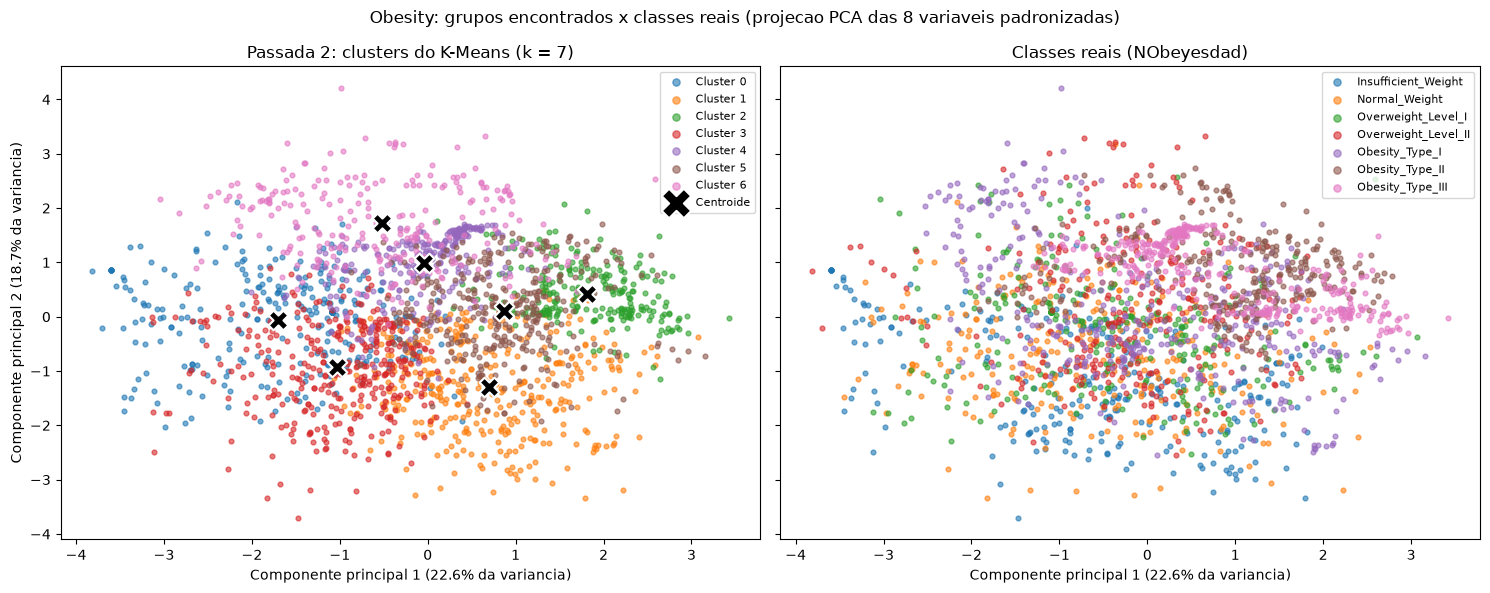

In [12]:
# [IA] Claude Code – grafico lado a lado: clusters do K-Means x classes reais, na mesma projecao PCA
ordem_classes = [
    "Insufficient_Weight", "Normal_Weight",
    "Overweight_Level_I", "Overweight_Level_II",
    "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III",
]
cores = plt.get_cmap("tab10").colors

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)

for i, cluster in enumerate(sorted(resultado_fixo["cluster"].unique())):
    filtro = resultado_fixo["cluster"].values == cluster
    ax1.scatter(coords[filtro, 0], coords[filtro, 1], s=12, alpha=0.6,
                color=cores[i], label=f"Cluster {cluster}")
ax1.scatter(centroides_2d[:, 0], centroides_2d[:, 1], marker="X", s=200,
            color="black", edgecolor="white", linewidth=1.5, label="Centroide")
ax1.set_title(f"Passada 2: clusters do K-Means (k = {K_FIXO})")

for i, classe in enumerate(ordem_classes):
    filtro = y.values == classe
    ax2.scatter(coords[filtro, 0], coords[filtro, 1], s=12, alpha=0.6,
                color=cores[i], label=classe)
ax2.set_title("Classes reais (NObeyesdad)")

for ax in (ax1, ax2):
    ax.set_xlabel(f"Componente principal 1 ({var_explicada[0]:.1f}% da variancia)")
    ax.legend(fontsize=8, markerscale=1.5, loc="best")
ax1.set_ylabel(f"Componente principal 2 ({var_explicada[1]:.1f}% da variancia)")

fig.suptitle("Obesity: grupos encontrados x classes reais (projecao PCA das 8 variaveis padronizadas)")
fig.tight_layout()

PASTA_SAIDA = Path("../../out/parte_comum")
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)
fig.savefig(PASTA_SAIDA / "passada2_clusters_pca.png", dpi=150, bbox_inches="tight")
plt.show()

**Por que esta visualização (decisão do grupo):** Escolhemos utilizar a dispersão dos componentes do PCA porque ela permite visualizar os grupos formados pelo K-Means em duas dimensões. Também decidimos manter a comparação com as classes reais para facilitar a identificação das semelhanças e diferenças entre os agrupamentos.


In [13]:
# [IA] Claude Code – quanto cada variavel pesa em cada componente (ajuda a ler os eixos do grafico)
pd.DataFrame(
    pca.components_.T,
    index=VARIAVEIS_KMEANS,
    columns=["PC1", "PC2"],
).round(3)

,PC1,PC2
Age,0.008,0.604
Height,0.598,-0.070
Weight,0.504,0.362
FCVC,0.162,0.260
NCP,0.333,-0.128
CH2O,0.385,-0.053
FAF,0.321,-0.362
TUE,0.015,-0.531


## Etapa 4: Mapeamento cluster → classe majoritária

In [14]:
# [IA] Claude Code – tabela de contagem: quantas pessoas de cada classe real caem em cada cluster
contagem_cluster_classe = pd.crosstab(
    resultado_fixo["cluster"],
    resultado_fixo["classe_real"],
)[ordem_classes]
contagem_cluster_classe

classe_real,Insufficient_Weight,Normal_Weight,Overweight_Level_I,Overweight_Level_II,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III
cluster,,,,,,,
0,53,49,64,31,54,29,0
1,125,83,65,52,38,0,0
2,0,0,5,4,23,84,137
3,84,102,69,57,55,0,0
4,7,26,9,20,7,5,187
5,0,16,34,63,95,126,0
6,3,11,44,63,79,53,0


In [15]:
# [IA] Claude Code – cada cluster recebe o nome da classe real que mais aparece dentro dele
mapa_cluster_classe = contagem_cluster_classe.idxmax(axis=1)

resumo_mapeamento = pd.DataFrame({
    "classe_majoritaria": mapa_cluster_classe,
    "qtd_classe_majoritaria": contagem_cluster_classe.max(axis=1),
    "qtd_total_cluster": contagem_cluster_classe.sum(axis=1),
})
resumo_mapeamento["pct_classe_majoritaria"] = (
    resumo_mapeamento["qtd_classe_majoritaria"] / resumo_mapeamento["qtd_total_cluster"] * 100
).round(1)
resumo_mapeamento

,classe_majoritaria,qtd_classe_majoritaria,qtd_total_cluster,pct_classe_majoritaria
cluster,,,,
0,Overweight_Level_I,64,280,22.9
1,Insufficient_Weight,125,363,34.4
2,Obesity_Type_III,137,253,54.2
3,Normal_Weight,102,367,27.8
4,Obesity_Type_III,187,261,71.6
5,Obesity_Type_II,126,334,37.7
6,Obesity_Type_I,79,253,31.2


In [16]:
# [IA] Claude Code – aplicar o mapeamento a cada linha (rotulo previsto usado na matriz de confusao)
resultado_fixo["classe_mapeada"] = resultado_fixo["cluster"].map(mapa_cluster_classe)

# Conferencia: classes reais que receberam mais de um cluster e classes que nao receberam nenhum
clusters_por_classe = mapa_cluster_classe.value_counts()
print("Clusters por classe mapeada:")
print(clusters_por_classe)
print("Classes reais sem nenhum cluster:", sorted(set(ordem_classes) - set(mapa_cluster_classe)))

resultado_fixo.head()

Clusters por classe mapeada:
Obesity_Type_III       2
Overweight_Level_I     1
Insufficient_Weight    1
Normal_Weight          1
Obesity_Type_II        1
Obesity_Type_I         1
Name: count, dtype: int64
Classes reais sem nenhum cluster: ['Overweight_Level_II']


,cluster,classe_real,classe_mapeada
0,3,Normal_Weight,Normal_Weight
1,1,Normal_Weight,Insufficient_Weight
2,1,Normal_Weight,Insufficient_Weight
3,2,Overweight_Level_I,Obesity_Type_III
4,0,Overweight_Level_II,Overweight_Level_I


## Etapa 5: Matriz de confusão e métricas

Linhas = classe real; colunas = classe mapeada a partir do cluster.

In [17]:
# [IA] Claude Code – matriz de confusao (quadrada: k = numero de classes)
from sklearn.metrics import confusion_matrix

matriz_fixo = pd.DataFrame(
    confusion_matrix(resultado_fixo["classe_real"], resultado_fixo["classe_mapeada"], labels=ordem_classes),
    index=pd.Index(ordem_classes, name="real"),
    columns=pd.Index(ordem_classes, name="mapeada"),
)
matriz_fixo

mapeada,Insufficient_Weight,Normal_Weight,Overweight_Level_I,Overweight_Level_II,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III
real,,,,,,,
Insufficient_Weight,125,84,53,0,3,0,7
Normal_Weight,83,102,49,0,11,16,26
Overweight_Level_I,65,69,64,0,44,34,14
Overweight_Level_II,52,57,31,0,63,63,24
Obesity_Type_I,38,55,54,0,79,95,30
Obesity_Type_II,0,0,29,0,53,126,89
Obesity_Type_III,0,0,0,0,0,0,324


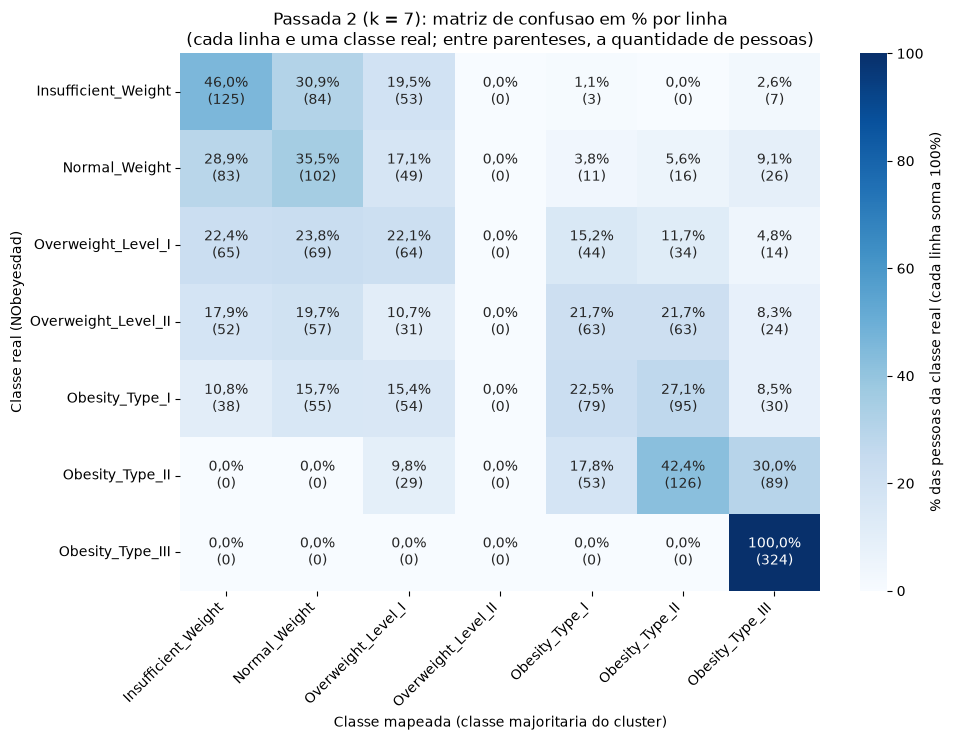

In [18]:
# [IA] Claude Code – heatmap da matriz de confusao em % por linha (cada classe real soma 100%), com a contagem em cada celula
import seaborn as sns

pct_linha = matriz_fixo.div(matriz_fixo.sum(axis=1), axis=0) * 100
rotulos = pct_linha.round(1).astype(str).replace(r"\.", ",", regex=True) + "%\n(" + matriz_fixo.astype(str) + ")"

fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(pct_linha, annot=rotulos, fmt="", cmap="Blues", vmin=0, vmax=100,
            cbar_kws={"label": "% das pessoas da classe real (cada linha soma 100%)"}, ax=ax)
ax.set_title(f"Passada 2 (k = {K_FIXO}): matriz de confusao em % por linha\n(cada linha e uma classe real; entre parenteses, a quantidade de pessoas)")
ax.set_xlabel("Classe mapeada (classe majoritaria do cluster)")
ax.set_ylabel("Classe real (NObeyesdad)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "passada2_matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()


**Por que esta visualização (decisão do grupo):** Escolhemos o mapa de calor com porcentagens por linha porque ele facilita a comparação entre as sete classes, mesmo quando possuem quantidades diferentes de pessoas. Também mantivemos as contagens absolutas nas células para não perder os valores reais.


In [19]:
# [IA] Claude Code – acuracia, precisao e recall calculados a partir da matriz
m = matriz_fixo.values
acertos = np.diag(m)                     # diagonal: real == mapeada
total_real = m.sum(axis=1)               # soma da linha: pessoas de cada classe real
total_mapeado = m.sum(axis=0)            # soma da coluna: pessoas rotuladas com cada classe

acuracia_fixo = acertos.sum() / m.sum()

# Precisao = acertos / total rotulado com a classe. Se nenhuma pessoa recebeu a classe
# (nenhum cluster mapeado para ela), a divisao e 0/0: registramos 0 e marcamos na tabela.
precisao = np.divide(acertos, total_mapeado, out=np.zeros(len(acertos)), where=total_mapeado > 0)
recall = acertos / total_real

metricas_fixo = pd.DataFrame({
    "precisao": precisao.round(3),
    "recall": recall.round(3),
    "qtd_real": total_real,
    "qtd_mapeada": total_mapeado,
    "sem_cluster_mapeado": total_mapeado == 0,
}, index=pd.Index(ordem_classes, name="classe"))

print(f"Acuracia (Passada 2): {acuracia_fixo:.3f}")
metricas_fixo

Acuracia (Passada 2): 0.388


,precisao,recall,qtd_real,qtd_mapeada,sem_cluster_mapeado
classe,,,,,
Insufficient_Weight,0.344,0.460,272,363,False
Normal_Weight,0.278,0.355,287,367,False
Overweight_Level_I,0.229,0.221,290,280,False
Overweight_Level_II,0.000,0.000,290,0,True
Obesity_Type_I,0.312,0.225,351,253,False
Obesity_Type_II,0.377,0.424,297,334,False
Obesity_Type_III,0.630,1.000,324,514,False


In [20]:
# [IA] Claude Code – conferencia com as funcoes do scikit-learn (devem dar os mesmos valores)
from sklearn.metrics import accuracy_score, precision_score, recall_score

args = dict(y_true=resultado_fixo["classe_real"], y_pred=resultado_fixo["classe_mapeada"], labels=ordem_classes)
assert np.isclose(accuracy_score(resultado_fixo["classe_real"], resultado_fixo["classe_mapeada"]), acuracia_fixo)
assert np.allclose(precision_score(average=None, zero_division=0, **args), precisao)
assert np.allclose(recall_score(average=None, zero_division=0, **args), recall)
print("Metricas conferem com o scikit-learn.")

Metricas conferem com o scikit-learn.
